### **BAGIAN 5: RANGKAIAN PRAPROSES SIMUTEH**


---

**Tujuan bagian**: menggabungkan seluruh temuan menjadi satu modul praproses yang
dapat dipakai ulang mulai Pertemuan 5, lengkap dengan parameter yang tersimpan dan
alasan setiap langkah

In [13]:
import sys
import os
from google.colab import drive

# Mount Drive
drive.mount('/content/drive')

# Pindah ke direktori repositori simuteh-1032
BASE_DIR = "/content/drive/MyDrive/simuteh-1032"
os.chdir(BASE_DIR)

# Daftarkan folder src ke dalam sys.path
sys.path.append(os.path.join(BASE_DIR, "src"))

print("Direktori aktif saat ini:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Direktori aktif saat ini: /content/drive/MyDrive/simuteh-1032


In [12]:
%%writefile src/praproses.py
"""
praproses.py: Rangkaian praproses SIMUTEH (dipakai ulang mulai P5).
"""
import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,          # sampling: lebar citra kerja (piksel)
    "gamma": 1.0,          # < 1 mencerahkan, > 1 menggelapkan
    "clahe_clip": 2.0,     # 0 berarti CLAHE tidak dipakai
    "clahe_tile": 8,
    "penapis": "median",   # "none", "rerata", "gaussian", "median"
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0         # 0 berarti tanpa penajaman
}

def praproses(img_bgr, p=None):
    """
    Urutan: Ubah ukuran -> Koreksi gamma -> CLAHE kanal V -> Redam derau -> Tajamkan.
    """
    p = {**PARAM_BAWAAN, **(p or {})}

    # 1. Ubah ukuran agar lebar = p["lebar"], rasio aspek tetap
    h, w = img_bgr.shape[:2]
    if w != p["lebar"]:
        tinggi_baru = int(h * (p["lebar"] / w))
        img = cv2.resize(img_bgr, (p["lebar"], tinggi_baru), interpolation=cv2.INTER_AREA)
    else:
        img = img_bgr.copy()

    # 2. Bila p["gamma"] != 1, terapkan koreksi gamma dengan cv2.LUT
    if p["gamma"] != 1.0:
        lut = np.array([255 * ((i / 255.0) ** p["gamma"]) for i in range(256)]).clip(0, 255).astype(np.uint8)
        img = cv2.LUT(img, lut)

    # 3. Bila p["clahe_clip"] > 0, ubah ke HSV, terapkan CLAHE pada kanal V saja, lalu kembalikan ke BGR
    if p["clahe_clip"] > 0:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"], tileGridSize=(p["clahe_tile"], p["clahe_tile"]))
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    # 4. Redam derau sesuai p["penapis"], p["kernel"], p["sigma"]
    k = p["kernel"]
    if p["penapis"] == "rerata":
        img = cv2.blur(img, (k, k))
    elif p["penapis"] == "gaussian":
        img = cv2.GaussianBlur(img, (k, k), p["sigma"])
    elif p["penapis"] == "median":
        img = cv2.medianBlur(img, k)

    # 5. Bila p["tajam_k"] > 0, lakukan unsharp masking
    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1.0 + p["tajam_k"], blur, -p["tajam_k"], 0)

    return img

def simpan_param(p, path="hasil/param_praproses.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)

Writing src/praproses.py


In [14]:
import pandas as pd
import cv2
import numpy as np
from utils_cv import baca, kontras_bercak
from praproses import praproses, simpan_param

# 1. Simpan parameter final ke JSON
param = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0
}
simpan_param(param, "hasil/param_praproses.json")

# 2. Hitung KB pada Kanal B (indeks 0 BGR)
KANAL = 0

label = pd.read_csv("data/sintetis/label.csv")
baris = []

for _, d in label[label.kelas != "sehat"].iterrows():
    img = baca(f"data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"data/sintetis/mask_daun/{d.nama_file}", 0)
    mb = cv2.imread(f"data/sintetis/mask_bercak/{d.nama_file}", 0)

    out = praproses(img, param)

    kb_sebelum = kontras_bercak(img[:, :, KANAL], md, mb)
    kb_sesudah = kontras_bercak(out[:, :, KANAL], md, mb)

    baris.append([d.kondisi_cahaya, kb_sebelum, kb_sesudah])

evaluasi = pd.DataFrame(baris, columns=["kondisi", "KB_sebelum", "KB_sesudah"])
tabel_12 = evaluasi.groupby("kondisi").mean().round(2)
tabel_12["Perubahan (%)"] = (((tabel_12["KB_sesudah"] - tabel_12["KB_sebelum"]) / tabel_12["KB_sebelum"]) * 100).round(1)

print("=== TABEL 12: EVALUASI RANGKAIAN PRAPROSES ===")
print(tabel_12)
tabel_12.to_csv("hasil/b5_evaluasi_praproses.csv")

=== TABEL 12: EVALUASI RANGKAIAN PRAPROSES ===
                KB_sebelum  KB_sesudah  Perubahan (%)
kondisi                                              
bayangan              1.31        2.71          106.9
gelap                 1.14        2.12           86.0
kontras_rendah        0.58        1.96          237.9
normal                1.97        3.62           83.8
terang                1.71        2.44           42.7


=== RERATA SIMPANGAN BAKU DAUN SEHAT ===
                Std_sebelum  Std_sesudah
kondisi                                 
bayangan              12.27         8.06
gelap                  9.12         5.39
kontras_rendah        11.05         9.78
normal                12.07         8.34
terang                11.54        10.82


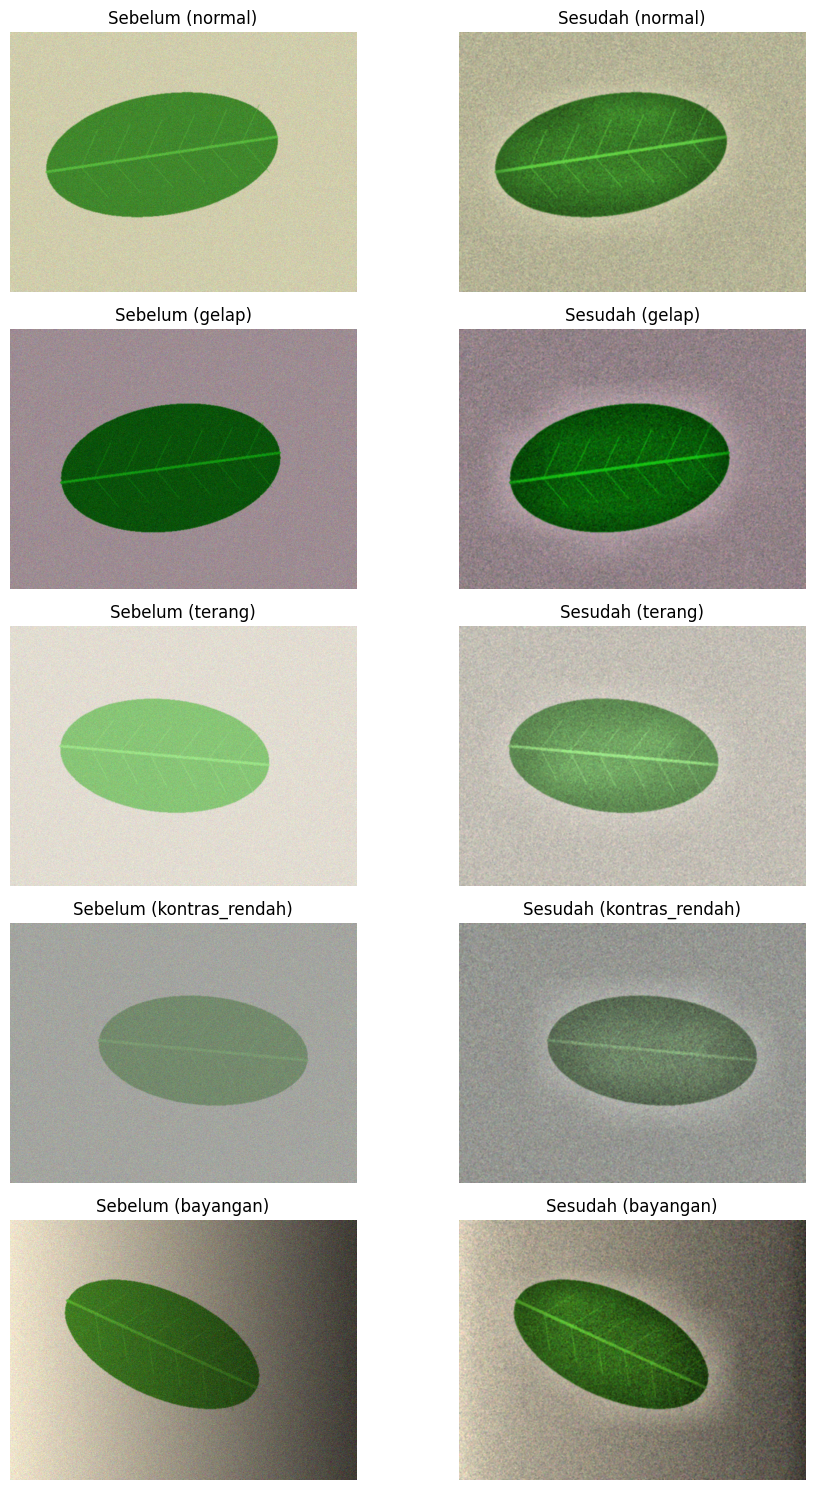

In [15]:
import matplotlib.pyplot as plt

baris_sehat = []
citra_contoh = {}

for _, d in label[label.kelas == "sehat"].iterrows():
    img = baca(f"data/sintetis/citra/{d.nama_file}")
    md = cv2.imread(f"data/sintetis/mask_daun/{d.nama_file}", 0)
    out = praproses(img, param)

    std_sebelum = img[:, :, KANAL][md > 0].std()
    std_sesudah = out[:, :, KANAL][md > 0].std()

    baris_sehat.append([d.kondisi_cahaya, std_sebelum, std_sesudah])

    if d.kondisi_cahaya not in citra_contoh:
        citra_contoh[d.kondisi_cahaya] = (img, out)

df_sehat = pd.DataFrame(baris_sehat, columns=["kondisi", "Std_sebelum", "Std_sesudah"]).groupby("kondisi").mean().round(2)
print("=== RERATA SIMPANGAN BAKU DAUN SEHAT ===")
print(df_sehat)

# Tampilkan Panel Sebelum & Sesudah
fig, axes = plt.subplots(5, 2, figsize=(10, 15))
for i, (kds, (im_ori, im_pros)) in enumerate(citra_contoh.items()):
    axes[i, 0].imshow(cv2.cvtColor(im_ori, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"Sebelum ({kds})")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(cv2.cvtColor(im_pros, cv2.COLOR_BGR2RGB))
    axes[i, 1].set_title(f"Sesudah ({kds})")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.savefig("hasil/b5_uji_bercak_palsu.png")
plt.show()